# Colisão kink–antikink no modelo $\phi^4$
### Um primeiro projeto de Iniciação Científica — 5 lições

**O que vamos fazer?** Construir uma simulação de duas paredes de domínio: um *kink* vindo da esquerda e um *antikink* vindo da direita. Eles se aproximam, colidem e podem escapar ou permanecer presos em um estado oscilante.

A ideia é escrever **pouco código, mas compreender cada linha**. Vamos usar somente `numpy`, `scipy` e `matplotlib`. A parte central terá **uma única função**, a equação de movimento. No fim, faremos um mapa de cores e uma animação.

**Como estudar:** leia a explicação antes de cada célula; complete apenas as linhas indicadas com `TODO`; execute as células na ordem. Não é preciso conhecer métodos avançados de programação.

---

## A física antes de começar

O campo $\phi(x,t)$ é um número real que depende da posição e do tempo. Imagine que, em cada ponto da linha, há uma pequena variável que prefere assumir um de dois valores: $+1$ ou $-1$. Isso acontece porque a energia potencial é

$$
V(\phi)=\frac12(1-\phi^2)^2.
$$

Esse potencial tem **dois mínimos**, $\phi=-1$ e $\phi=+1$, ambos com energia potencial zero. Chamamos esses valores de *vácuos*. Uma região com $\phi=-1$ pode estar ao lado de outra com $\phi=+1$. Entre elas aparece uma transição espacial localizada: o **kink**.

A densidade de Lagrangiana do modelo, em unidades adimensionais, é

$$
\mathcal{L}=\frac12\phi_t^2-\frac12\phi_x^2-V(\phi).
$$

Da equação de Euler–Lagrange obtemos

$$
\phi_{tt}=\phi_{xx}-\frac{dV}{d\phi}
          =\phi_{xx}+2\phi(1-\phi^2).
$$

**Interpretação:** $\phi_{xx}$ descreve o acoplamento espacial entre regiões vizinhas do campo; $2\phi(1-\phi^2)$ é a força local produzida pelo potencial. Nosso trabalho será resolver numericamente essa equação diferencial parcial.

## Lição 1 — Entender `numpy.roll` e calcular o laplaciano

O computador não conhece uma função contínua em todos os pontos de $x$. Ele conhece uma lista de valores em uma malha:

$$
x_i = -L+i\,\Delta x,\qquad \phi_i\approx\phi(x_i).
$$

Para calcular a segunda derivada espacial, usamos a **diferença finita central**:

$$
\left.\frac{\partial^2\phi}{\partial x^2}\right|_{x_i}
\approx\frac{\phi_{i+1}-2\phi_i+\phi_{i-1}}{(\Delta x)^2}.
$$

Em uma dimensão, o laplaciano $\nabla^2\phi$ é precisamente essa segunda derivada. A fórmula tem uma interpretação simples: compara o valor de um ponto com seus dois vizinhos.

Em Python, `np.roll(a, -1)` traz o vizinho da direita para cada posição e `np.roll(a, 1)` traz o vizinho da esquerda. Observe:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

a = np.array([10, 20, 30, 40])
print("original: ", a)
print("roll -1: ", np.roll(a, -1))
print("roll +1: ", np.roll(a,  1))

original:  [10 20 30 40]
roll -1:  [20 30 40 10]
roll +1:  [40 10 20 30]


Note que o último elemento volta para a primeira posição (e vice-versa): `roll` faz uma **continuação periódica da lista**. Portanto, nossa simulação usará condições de contorno periódicas. Isso não significa que os kinks precisam interagir com suas cópias: escolheremos um domínio grande o bastante para que, durante o tempo estudado, a colisão ocorra longe das bordas.

**Sua tarefa:** crie uma malha e implemente a fórmula da segunda derivada. Testaremos usando $f(x)=e^{-x^2}$, cuja derivada exata é $f''(x)=(4x^2-2)e^{-x^2}$. Se as curvas se sobrepuserem, você entendeu a ideia.

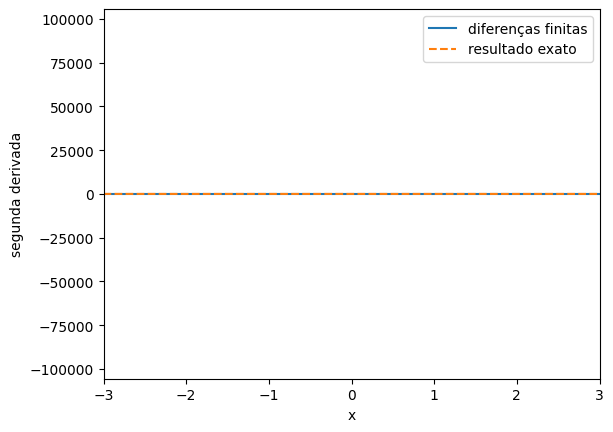

In [ ]:
L = 120
dx = 0.05

x = np.arange(-L, L, dx)
N = len(x)

f = np.exp(-x**2)

# TODO 1: implemente f'' usando np.roll e dx.
f_xx = (np.roll(x,1) - 2*x + np.roll(x,-1))/dx**2

plt.plot(x, f_xx, label="diferenças finitas")
plt.plot(x, (4*x**2 - 2)*f, "--", label="resultado exato")
plt.xlim(-3, 3)
plt.xlabel("x")
plt.ylabel("segunda derivada")
plt.legend()
plt.show()

**Pergunta:** por que não é necessário escrever um `for` para percorrer os pontos? A resposta é a **vetorização**: o NumPy realiza a operação sobre todo o vetor.

## Lição 2 — Transformar a equação física em uma função para o `solve_ivp`

O `solve_ivp` resolve problemas de primeira ordem, escritos como $dy/dt=F(t,y)$. Mas nossa equação contém $\phi_{tt}$, uma segunda derivada temporal. O truque é introduzir outra variável:

$$
\pi(x,t)=\frac{\partial\phi}{\partial t}.
$$

A equação original passa a ser o **sistema de duas equações de primeira ordem**:

$$
\begin{aligned}
\frac{\partial\phi}{\partial t}&=\pi,\\
\frac{\partial\pi}{\partial t}&=\phi_{xx}+2\phi(1-\phi^2).
\end{aligned}
$$

No computador, $\phi$ e $\pi$ são dois vetores de comprimento `N`. Para que o `solve_ivp` receba apenas um vetor, juntamos os dois:

$$
y=(\phi_0,\ldots,\phi_{N-1},\pi_0,\ldots,\pi_{N-1}).
$$

Assim, `y[:N]` contém o campo e `y[N:]` contém sua velocidade temporal. **Não confunda $\pi$ com o número 3,14159:** aqui $\pi$ é apenas o nome da variável $\partial_t\phi$.

**Sua tarefa:** complete as duas expressões abaixo. A primeira é a mesma diferença finita da lição 1; a segunda vem diretamente da equação de movimento. Esta será **a única função física do notebook**.

In [ ]:
def equacao(t, y):
    phi = y[:N]
    pi = y[N:]

    # TODO 2: segunda derivada espacial de phi.
    phi_xx = (np.roll(phi,1)-2*phi+np.roll(phi,-1))/dx**2

    dphi = pi

    # TODO 3: equação para a derivada temporal de pi.
    dpi = phi_xx + 2*phi*(1-phi**2)

    return np.concatenate((dphi, dpi))

**Por que a função recebe `t` se não aparece explicitamente na equação?** Porque essa é a interface que o `solve_ivp` exige. Neste modelo a lei física não depende diretamente do tempo; ela depende dos valores atuais de $\phi$ e $\pi$.

## Lição 3 — Preparar a condição inicial: um kink e um antikink

Uma solução estática do modelo é

$$\phi_K(x)=\tanh(x-X),$$

em que $X$ é a posição do centro do kink. Ela sai de $-1$ à esquerda e chega a $+1$ à direita. O **antikink** tem orientação oposta:

$$\phi_{\bar K}(x)=-\tanh(x-X).$$

O modelo é relativístico: um kink que se move com velocidade $v$ fica contraído por $\gamma=1/\sqrt{1-v^2}$ (nessas unidades, a velocidade-limite é $1$). Queremos inicialmente o kink centrado em $-x_0$, movendo-se para a direita, e o antikink centrado em $+x_0$, movendo-se para a esquerda.

Uma condição inicial simples é a superposição

$$
\phi(x,0)=\tanh[\gamma(x+x_0)]-\tanh[\gamma(x-x_0)]-1.
$$

O termo $-1$ é importante: longe das duas paredes, o campo deve tender ao mesmo vácuo, $\phi=-1$. Entre elas, tende a $+1$. Esta superposição é **aproximada**, não uma solução exata para dois sólitons próximos; funciona bem quando a separação inicial $2x_0$ é grande em relação à largura das paredes.

Precisamos também de $\pi(x,0)=\phi_t(x,0)$. Como $d\tanh z/dz=1/\cosh^2 z$, derivando as soluções **que se aproximam uma da outra** obtemos

$$
\pi(x,0)=-\gamma v\left[
\frac{1}{\cosh^2\!\big(\gamma(x+x_0)\big)}+
\frac{1}{\cosh^2\!\big(\gamma(x-x_0)\big)}
\right].
$$

Note que os dois termos têm sinal negativo: no início, as duas paredes reduzem o valor do campo nos respectivos centros enquanto avançam para a região intermediária.

**Sua tarefa:** transcreva essas duas fórmulas em NumPy. Para deixar o código limpo, já definimos `a` e `b` como os argumentos das funções hiperbólicas.

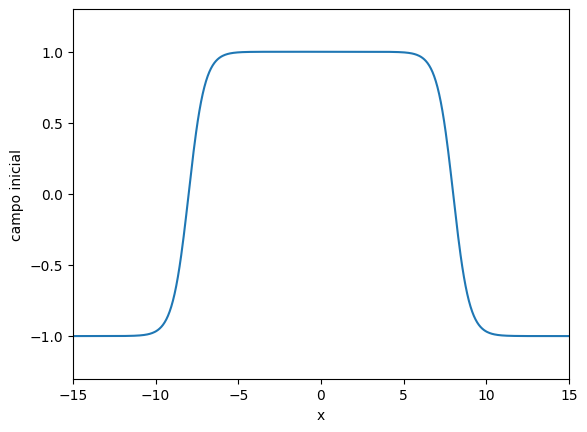

In [ ]:
v = 0.23
x0 = 8.0

gamma = 1 / np.sqrt(1 - v**2)
a = gamma * (x + x0)
b = gamma * (x - x0)

# TODO 4: campo inicial (use np.tanh).
phi0 = np.tanh(a) - np.tanh(b) - 1

# TODO 5: velocidade inicial (use np.cosh).
pi0 = -gamma*v*((1/np.cosh(a)**2)+(1/np.cosh(b)**2))

y0 = np.concatenate((phi0, pi0))

plt.plot(x, phi0)
plt.xlim(-15, 15)
plt.ylim(-1.3, 1.3)
plt.xlabel("x")
plt.ylabel("campo inicial")
plt.show()

**Antes de continuar:** o gráfico deve mostrar duas transições separadas aproximadamente por $2x_0=16$. Confira mentalmente os valores do campo à esquerda, entre as paredes e à direita. Se você vir uma única transição, há um problema de sinal na condição inicial.

## Lição 4 — Pedir ao `solve_ivp` que evolua o campo

Agora temos tudo o que o integrador precisa:

- A **lei de evolução**, `equacao(t, y)`;
- O **estado inicial**, `y0`;
- O **intervalo de tempo** durante o qual queremos acompanhar a colisão.

O `solve_ivp` escolhe internamente passos de integração para controlar o erro numérico. O argumento `t_eval` indica **em quais instantes guardar a resposta**, não obriga o integrador a usar esses valores como passos internos. Cada coluna de `sol.y` será um instante; as primeiras `N` linhas são $\phi(x,t)$, e as demais são $\pi(x,t)$.

Usaremos $t$ de $0$ a $140$ e guardaremos um estado a cada $0{,}5$ unidade de tempo. Como a malha tem $\Delta x=0{,}1$ e as colisões podem ser sensíveis a pequenas perturbações, manteremos tolerâncias numéricas moderadamente exigentes.

**Sua tarefa:** faça a chamada ao integrador.

In [ ]:
tempos = np.linspace(0, 140, 281)

# TODO 6: use solve_ivp com equacao, intervalo (0, 140), y0 e t_eval=tempos.
sol = solve_ivp(equacao,(0,140),y0,t_eval=tempos)

print("Integração concluída?", sol.success)
print("Formato dos resultados:", sol.y.shape)

Integração concluída? True
Formato dos resultados: (9600, 281)


Você espera `sol.y.shape == (2*N, 281)`. Se `sol.success` não for `True`, há algum problema na integração. **Não confunda erro de programação com fenômeno físico:** antes de interpretar colisões, confira se o programa realmente terminou a evolução solicitada.

## Lição 5 — Enxergar a colisão com o Matplotlib

Uma simulação fornece muitos números; precisamos transformá-los em algo que o olho possa interpretar. Faremos duas visualizações do **mesmo resultado**, sem repetir a integração.

### 5.1 Mapa de cores no espaço e no tempo

Cada ponto da imagem corresponde a um valor de $\phi(x,t)$. No mapa abaixo:

- O eixo horizontal indica **posição** $x$;
- O eixo vertical indica **tempo** $t$;
- A cor indica **o valor do campo** (consulte a barra de cores).

As paredes de domínio aparecem como faixas inclinadas que se aproximam. Se elas mudarem de direção, podemos ter reflexão. Se continuarem presas na região central, formam uma estrutura oscilante que chamamos de **bion**. Em certas velocidades, elas se chocam, se afastam um pouco, voltam a colidir e só depois escapam: são as **janelas de ressonância**.

O comando `sol.y[:N, :]` extrai o campo em todos os tempos; usamos `.T` para colocar **tempo nas linhas** e **posição nas colunas**, como o `imshow` espera.

O código para desenhar o mapa está completo; observe especialmente a transposição `.T` e o parâmetro `extent`.

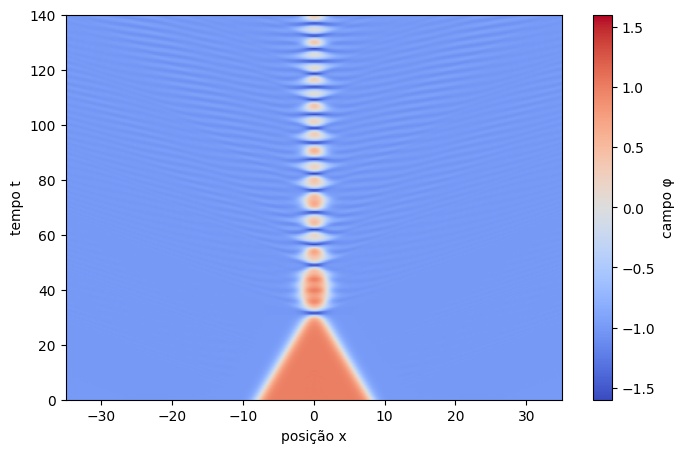

In [ ]:
plt.figure(figsize=(8, 5))
plt.imshow(sol.y[:N, :].T, origin="lower", aspect="auto",
           extent=[x[0], x[-1], sol.t[0], sol.t[-1]],
           cmap="coolwarm", vmin=-1.6, vmax=1.6)
plt.xlim(-35, 35)
plt.xlabel("posição x")
plt.ylabel("tempo t")
plt.colorbar(label="campo φ")
plt.show()

### 5.2 Uma animação do campo

O mapa resume a evolução inteira em uma só imagem. A animação mostra outra perspectiva: **o perfil espacial mudando com o tempo**. A linha começa com duas paredes separadas, depois evolui conforme a solução numérica.

`FuncAnimation` atualiza uma linha que já foi desenhada. Para evitar introduzir outra função longa, usamos uma expressão curta com `lambda`: ela simplesmente substitui os valores verticais da curva pelos valores de $\phi$ no instante escolhido. **Não é preciso memorizar a sintaxe da animação; o objetivo é interpretar a física.**

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots()
linha, = ax.plot(x, sol.y[:N, 0])
ax.set(xlim=(-35, 35), ylim=(-1.8, 1.8), xlabel="x", ylabel="φ")

anim = FuncAnimation(fig,
                     lambda j: linha.set_ydata(sol.y[:N, j]),
                     frames=range(0, len(sol.t), 3), interval=70)
plt.close(fig)
HTML(anim.to_jshtml())

### Investigação física: varie somente `v`

Agora não é necessário escrever mais funções. Troque **apenas** o valor de `v` na lição 3 e reexecute a partir dela. Experimente estes valores como pontos de partida (eles podem mudar um pouco de comportamento com a resolução espacial e a separação inicial):

| Velocidade inicial | O que procurar no mapa e na animação |
|---|---|
| $v\approx0{,}28$ | Colisão seguida de separação rápida das paredes: **escape após o primeiro encontro**. |
| $v\approx0{,}10$ | **Captura**: uma região oscilante permanece próxima do centro, irradiando energia — o **bion**. |
| $v\approx0{,}225$ | **Possível janela de ressonância**: as paredes se chocam, se separam parcialmente, tornam a se encontrar e escapam. |

**Atenção à linguagem física:** a colisão pode parecer uma “reflexão” no mapa, mas kink e antikink não são partículas rígidas com etiquetas. O que observamos são as paredes de domínio; a evolução completa do campo determina o processo.

### Por que existem janelas de ressonância?

Um kink isolado possui um modo interno de oscilação, além do movimento de seu centro. Na primeira colisão, parte da energia translacional pode passar para essa vibração e para a radiação do campo. Se os kinks se afastarem pouco, a atração pode trazê-los de volta. Em determinadas velocidades, a fase da vibração interna no reencontro favorece a **devolução de energia para o movimento de separação**. Assim, após dois ou mais impactos, o par consegue escapar. Esse mecanismo é frequentemente chamado de *ressonância entre o movimento translacional e o modo interno*.

Isso explica por que pequenos ajustes de $v$ podem produzir resultados muito diferentes. As posições das janelas **não são universais**: o valor observado depende do modelo e, numericamente, da resolução, das condições iniciais e do tempo disponível.

### Perguntas para responder no caderno de IC

1. Quais são os dois vácuos do modelo? Como o kink conecta esses estados?

Os vácuos são representados pelos estados de $\phi=\pm 1$, o kink seria uma região onde há transição de energia de um estado ao outro.

2. Por que foi necessário criar a variável $\pi$ antes de chamar o `solve_ivp`?

Foi necessário para criar dois vetores solução utilizáveis pelo solve_ivp. A equação que antes se tratava de uma EDO de segunda ordem, não resolvível pela função, pôde ser traduzida como duas EDPs.

3. Como o mapa de cores permite contar aproximadamente quantos encontros ocorreram?

Podemos observar as regiões que formam linhas horizontais azuis, onde o lado esquerdo e direito do mapa se econtraram.

4. O que distingue um bion de dois kinks que simplesmente se afastam?

Um bion é caracterizado por uma oscilação contínua dos kinks, que permanecem em contato por um tempo maior, sem se afastar.

5. Ao mudar $v$ um pouco perto de uma janela de ressonância, o resultado é sempre parecido? O que isso sugere sobre a dinâmica não linear?

Uma mudança mínima perto da janela de ressonância é suficiente para sair dela. Isso sugere um modelo de sistema caótico

**Verificação numérica útil:** se você observar uma colisão estranha, diminua `dx` e compare os mapas. Fenômenos físicos devem permanecer qualitativamente semelhantes quando a malha é refinada; janelas muito estreitas podem se deslocar porque são sensíveis a pequenos erros.

---

**Referência para aprofundamento:** D. K. Campbell, J. F. Schonfeld e C. A. Wingate, *Resonance structure in kink-antikink interactions in $\phi^4$ theory*, Physica D **9**, 1–32 (1983). O mecanismo de troca de energia com o modo interno também é discutido em revisões modernas sobre colisões de kinks.